In [1]:
import numpy as np
import tensorflow as tf
import re

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Lambda, Dense
from tensorflow.keras.utils import to_categorical

In [2]:
corpus = """
I love machine learning
I love deep learning
machine learning is interesting
deep learning is powerful
I enjoy learning new things
machine learning is useful
I love artificial intelligence
artificial intelligence is amazing
"""

print(corpus)


I love machine learning
I love deep learning
machine learning is interesting
deep learning is powerful
I enjoy learning new things
machine learning is useful
I love artificial intelligence
artificial intelligence is amazing



In [3]:
# Convert text to lowercase
corpus = corpus.lower()

# Remove punctuation
corpus = re.sub(r'[^\w\s]', '', corpus)

# Tokenize sentences into words
sentences = corpus.split('\n')

# Remove empty sentences
sentences = [sentence.split() for sentence in sentences if sentence.strip()]

print("Tokenized sentences:")
for sentence in sentences:
    print(sentence)

Tokenized sentences:
['i', 'love', 'machine', 'learning']
['i', 'love', 'deep', 'learning']
['machine', 'learning', 'is', 'interesting']
['deep', 'learning', 'is', 'powerful']
['i', 'enjoy', 'learning', 'new', 'things']
['machine', 'learning', 'is', 'useful']
['i', 'love', 'artificial', 'intelligence']
['artificial', 'intelligence', 'is', 'amazing']


In [4]:
# Create vocabulary
vocabulary = sorted(set(word for sentence in sentences for word in sentence))

# Assign unique index to each word
word_to_index = {
    word: index for index, word in enumerate(vocabulary)
}

index_to_word = {
    index: word for word, index in word_to_index.items()
}

vocab_size = len(vocabulary)

print("Vocabulary:", vocabulary)
print("Word to Index:", word_to_index)
print("Vocabulary Size:", vocab_size)

Vocabulary: ['amazing', 'artificial', 'deep', 'enjoy', 'i', 'intelligence', 'interesting', 'is', 'learning', 'love', 'machine', 'new', 'powerful', 'things', 'useful']
Word to Index: {'amazing': 0, 'artificial': 1, 'deep': 2, 'enjoy': 3, 'i': 4, 'intelligence': 5, 'interesting': 6, 'is': 7, 'learning': 8, 'love': 9, 'machine': 10, 'new': 11, 'powerful': 12, 'things': 13, 'useful': 14}
Vocabulary Size: 15


In [5]:
window_size = 2

contexts = []
targets = []

for sentence in sentences:

    for i in range(window_size, len(sentence) - window_size):

        context_words = (
            sentence[i-window_size:i] +
            sentence[i+1:i+window_size+1]
        )

        target_word = sentence[i]

        context_indices = [
            word_to_index[word] for word in context_words
        ]

        target_index = word_to_index[target_word]

        contexts.append(context_indices)
        targets.append(target_index)

X = np.array(contexts)
y = np.array(targets)

print("Context samples:")
print(X[:5])

print("\nTarget samples:")
print(y[:5])

print("\nContext words:", len(X))

Context samples:
[[ 4  3 11 13]]

Target samples:
[8]

Context words: 1


In [6]:
y = to_categorical(y, num_classes=vocab_size)

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (1, 4)
Output shape: (1, 15)


In [7]:
embedding_dim = 50

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        input_length=window_size * 2
    ),

    Lambda(lambda x: tf.reduce_mean(x, axis=1)),

    Dense(vocab_size, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

C:\Users\saniya maner\miniconda3\envs\tensorflow_env\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lambda (Lambda)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    X,
    y,
    epochs=200,
    verbose=1
)

Epoch 1/200

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.0000e+00 - loss: 2.7018
Epoch 2/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.0000e+00 - loss: 2.6910
Epoch 3/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 1.0000 - loss: 2.6802
Epoch 4/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 1.0000 - loss: 2.6694
Epoch 5/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 1.0000 - loss: 2.6586
Epoch 6/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 1.0000 - loss: 2.6478
Epoch 7/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 1.0000 - loss: 2.6369
Epoch 8/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 1.0000 - loss: 2.6259
Epoch 9/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 1.0000 - loss: 2.6149
Epoch 10/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 1.0000 - loss: 2.6038
Epoch 11/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 1.0000 - loss: 2.5927
Epoch 12/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 1.00

Final Training Loss: 0.0802745670080185


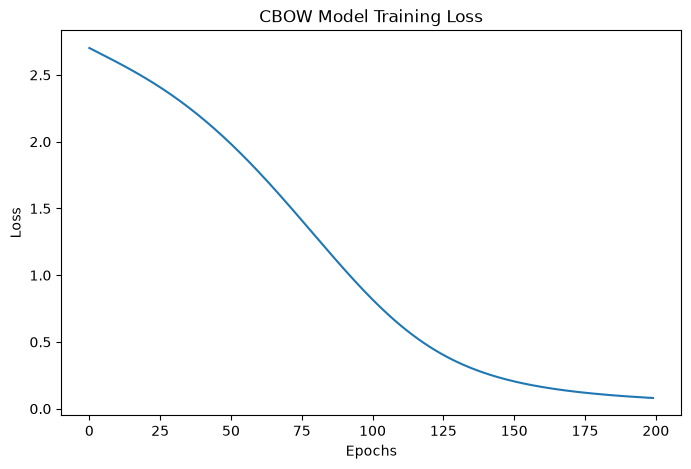

In [9]:
print("Final Training Loss:", history.history['loss'][-1])

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'])

plt.title("CBOW Model Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.show()

In [10]:
def predict_word(context_words):

    context_indices = [
        word_to_index[word.lower()]
        for word in context_words
    ]

    context_array = np.array([context_indices])

    prediction = model.predict(context_array, verbose=0)

    predicted_index = np.argmax(prediction)

    return index_to_word[predicted_index]


context_words = ['i', 'love', 'learning', 'is']

predicted_word = predict_word(context_words)

print("Context words:", context_words)
print("Predicted target word:", predicted_word)

Context words: ['i', 'love', 'learning', 'is']
Predicted target word: learning


In [11]:
print("Sample CBOW Training Pairs:\n")

for i in range(min(10, len(X))):

    context_words = [
        index_to_word[index] for index in X[i]
    ]

    target_word = index_to_word[np.argmax(y[i])]

    print("Context:", context_words)
    print("Target:", target_word)
    print("-------------------------")

Sample CBOW Training Pairs:

Context: ['i', 'enjoy', 'new', 'things']
Target: learning
-------------------------


In [ ]:
# 28.CBOW Model for Word Prediction
# Implement a Continuous Bag of Words (CBOW) model using Python to
# predict a target word based on its surrounding context words. Perform the
# following steps:
# a. Data Preparation: Create a sample text corpus, convert the text into
# lowercase, remove punctuation and tokenize the sentences into words.
# b. Generate Training Data: Build a vocabulary, assign a unique index to each
# word and generate CBOW training pairs consisting of context words and their
# corresponding target words.
# c. Train Model: Build a simple CBOW neural network using an Embedding
# layer and Dense layer. Train the model using the generated training data to
# learn word representations.
# d. Output: Display the vocabulary, sample context-target pairs, training loss and
# predicted target word for a given set of context words.